In [194]:
import pandas as pd
import matplotlib.pyplot as plt

In [195]:
def load_midas_data(file_path, skip_rows, rework_time=True):
    """Carrega um arquivo do MIDAS, criando uma coluna de início da observação e pulando o header do arquivo."""
    df = pd.read_csv(file_path, skiprows=skip_rows, skipfooter=1, engine='python')
    if rework_time:
        df['ob_end_time'] = pd.to_datetime(df['ob_end_time'], format='%Y-%m-%d %H:%M:%S')
        # ob_start_time = ob_end_time - 1
        df['ob_start_time'] = df['ob_end_time'] - pd.Timedelta(hours=1)
    else:
        df['ob_time'] = pd.to_datetime(df['ob_time'], format='%Y-%m-%d %H:%M:%S')
    return df

In [196]:
def load_tfl_data(file_path):
    """
    Carrega um arquivo de dados de tráfego do TFL.
    Nem todos os arquivos tem tipo de veículo, então usamos só a qtd., até para simplificar o dataset.
    Fazemos a soma por data/hora pois os arquivos tem diferenciação por faixa (lane).
    """
    df = pd.read_csv(file_path)
    # format 13/03/2017 (2017 only), 2023-01-19 18:00:00 otherwise
    try:
        df['Sdate'] = pd.to_datetime(df['Sdate'], format='%Y-%m-%d %H:%M:%S')
    except ValueError:
        df['Sdate'] = pd.to_datetime(df['Sdate'], format='%d/%m/%Y %H:%M')
    df = df[['Sdate', 'Volume']].rename(columns={'Sdate': 'time', 'Volume': 'vehicle_count'})
    df = df.groupby('time').sum().reset_index()
    return df

In [197]:
def load_aurn_data(file_path):
    """
    Carrega um arquivo de dados de poluentes do AURN.
    """
    df = pd.read_csv(file_path, skiprows=17)
    df = df[['Date', 'Time', 'Ozone', 'PM2.5 particulate matter (Hourly measured)']]
    # drop "End" date row
    df = df[df['Date'] != 'End']
    # convert 24:00:00 to 00:00:00 of same day
    df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')
    df['Time'] = df['Time'].replace('24:00:00', '00:00:00')
    df['DateTime'] = pd.to_datetime(df['Date'].dt.strftime('%Y-%m-%d') + ' ' + df['Time'], format='%Y-%m-%d %H:%M:%S')
    # rename
    df = df.rename(columns={'Ozone': 'ozone', 'PM2.5 particulate matter (Hourly measured)': 'pm25'})
    df = df[['DateTime', 'ozone', 'pm25']]
    df = df.sort_values('DateTime').reset_index(drop=True)
    return df

In [198]:
BASE_PATH = "../data/bronze/"

## Metheorological data from MIDAS (Met Office Integrated Data Archive System) - UK

In [199]:
# rain - London St James's Park (~2,5km from Marylebone Road)
df_rain = pd.DataFrame(columns=['ob_start_time', 'prcp_amt'])
for i in range(17, 24):
    fp = BASE_PATH + f"rain/midas-open_uk-hourly-rain-obs_dv-202607_greater-london_00697_london-st-jamess-park_qcv-1_20{i}.csv"
    df_rain_sub = load_midas_data(fp, skip_rows=64)
    # selecting only needed columns
    # prcp_amt = Precipitation amount | mm
    df_rain_sub = df_rain_sub[['ob_start_time', 'prcp_amt']]
    # append
    df_rain = pd.concat([df_rain, df_rain_sub], ignore_index=True)

In [200]:
# radiation - Kew Gardens (~10km de Marylebone road)
df_radiation = pd.DataFrame(columns=['ob_start_time', 'glbl_irad_amt'])
for i in range(17, 24):
    fp = BASE_PATH + f"radiation/midas-open_uk-radiation-obs_dv-202607_greater-london_00723_kew-gardens_qcv-1_20{i}.csv"
    df_radiation_sub = load_midas_data(fp, skip_rows=78)
    # glbl_irad_amt = Global solar irradiation amount | KJ/m2
    df_radiation_sub = df_radiation_sub[['ob_start_time', 'glbl_irad_amt']]
    df_radiation = pd.concat([df_radiation, df_radiation_sub], ignore_index=True)

In [201]:
# weather 1 - London St James's Park (~2,5km from Marylebone Road)
# weather 1 = rel. humidity, air temperature
df_weather1 = pd.DataFrame(columns=['ob_start_time', 'air_temperature', 'rltv_hum'])
for i in range(17, 24):
    fp = BASE_PATH + f"weather/midas-open_uk-hourly-weather-obs_dv-202607_greater-london_00697_london-st-jamess-park_qcv-1_20{i}.csv"
    df_weather1_sub = load_midas_data(fp, skip_rows=283, rework_time=False).rename(columns={'ob_time': 'ob_start_time'})
    # air_temperature = Air temperature | degC
    # rltv_hum = Calculated relative humidity | %
    df_weather1_sub = df_weather1_sub[['ob_start_time', 'air_temperature', 'rltv_hum']]
    df_weather1 = pd.concat([df_weather1, df_weather1_sub], ignore_index=True)

In [202]:
# weather 2 - Battersea Heliport (~5km from Marylebone road)
# weather 2 = rel. humidity, air temperature
df_weather2 = pd.DataFrame(columns=['ob_start_time', 'wind_speed', 'wind_direction', 'msl_pressure'])
for i in range(18, 24):
    fp = BASE_PATH + f"weather/midas-open_uk-hourly-weather-obs_dv-202607_greater-london_62084_battersea-heliport_qcv-1_20{i}.csv"
    df_weather2_sub = load_midas_data(fp, skip_rows=283, rework_time=False).rename(columns={'ob_time': 'ob_start_time'})
    # wind_speed = wind speed | knots
    # wind_direction = wind direction in true degrees
    # msl_pressure = mean sea level air pressure | hPa
    df_weather2_sub = df_weather2_sub[['ob_start_time', 'wind_speed', 'wind_direction', 'msl_pressure']]
    df_weather2 = pd.concat([df_weather2, df_weather2_sub], ignore_index=True)

In [203]:
df_weather2.head()

,ob_start_time,wind_speed,wind_direction,msl_pressure
0,2018-05-21 00:00:00,2.0,130.0,1019.8
1,2018-05-21 01:00:00,2.0,150.0,1019.2
2,2018-05-21 02:00:00,2.0,120.0,1018.7
3,2018-05-21 03:00:00,1.0,140.0,1018.1
4,2018-05-21 04:00:00,1.0,140.0,1017.9


## Vehicle traffic volume from TfL (Transport for London) ATC 227 - UK

In [204]:
df_vehicle = pd.DataFrame(columns=['time', 'vehicle_count'])
for i in range(17, 24):
    fp = BASE_PATH + f"vehicle/Mary Rd_ATC227_20{i}.csv"
    df_vehicle_sub = load_tfl_data(fp)
    df_vehicle = pd.concat([df_vehicle, df_vehicle_sub], ignore_index=True)

# Gabriel pointed out a considerable amount of zeroed values
# I initially assumed those were simply periods of no traffic, but checking the average
# volume as reported anually by TFL, I realized that that is very unlikely
# so we will discard those rows
df_vehicle = df_vehicle[df_vehicle['vehicle_count'] > 0].reset_index(drop=True)

In [205]:
df_vehicle.head()

,time,vehicle_count
0,2017-01-01 00:00:00,2842
1,2017-01-01 01:00:00,3106
2,2017-01-01 02:00:00,3208
3,2017-01-01 03:00:00,3235
4,2017-01-01 04:00:00,3261


## BLH from ERA5

In [206]:
df_blh = pd.DataFrame(columns=['time_utc', 'blh_m'])
for i in range(17, 24):
    fp = BASE_PATH + f"blh/my1_era5_blh_20{i}.csv"
    df_blh_sub = pd.read_csv(fp, skiprows=4)
    df_blh_sub['time_utc'] = pd.to_datetime(df_blh_sub['time_utc'], format='%Y-%m-%d %H:%M:%S')
    df_blh_sub = df_blh_sub[['time_utc', 'blh_m']]
    df_blh = pd.concat([df_blh, df_blh_sub], ignore_index=True)

In [207]:
df_blh.head()

,time_utc,blh_m
0,2017-01-01 00:00:00,445.59033
1,2017-01-01 01:00:00,461.58887
2,2017-01-01 02:00:00,461.9287
3,2017-01-01 03:00:00,434.40625
4,2017-01-01 04:00:00,432.81787


## PM2.5 and O3 concentrations from AURN
London Marylebone Road

In [208]:
df_pollutants = pd.DataFrame(columns=['DateTime', 'ozone', 'pm25'])

for i in range(17, 24):
    fp = BASE_PATH + f"pollutant/AirQualityDataHourly20{i}.csv"
    df_pollutants_sub = load_aurn_data(fp)
    df_pollutants = pd.concat([df_pollutants, df_pollutants_sub], ignore_index=True)

In [209]:
df_pollutants.head(30)

,DateTime,ozone,pm25
0,2017-01-01 00:00:00,36.52131,3
1,2017-01-01 01:00:00,10.57721,31.5
2,2017-01-01 02:00:00,5.1223,33.6
3,2017-01-01 03:00:00,7.13463,25.6
4,2017-01-01 04:00:00,6.78538,23.1
5,2017-01-01 05:00:00,7.53377,23.1
6,2017-01-01 06:00:00,5.18882,24.7
7,2017-01-01 07:00:00,7.43398,24
8,2017-01-01 08:00:00,6.43613,21
9,2017-01-01 09:00:00,4.29076,23


## Joining data

In [210]:
# renaming time columns to have a consistent name across all datasets
df_rain = df_rain.rename(columns={'ob_start_time': 'datetime'})
df_radiation = df_radiation.rename(columns={'ob_start_time': 'datetime'})
df_weather1 = df_weather1.rename(columns={'ob_start_time': 'datetime'})
df_weather2 = df_weather2.rename(columns={'ob_start_time': 'datetime'})
df_vehicle = df_vehicle.rename(columns={'time': 'datetime'})
df_blh = df_blh.rename(columns={'time_utc': 'datetime'})
df_pollutants = df_pollutants.rename(columns={'DateTime': 'datetime'})

In [211]:
df_joined = df_pollutants.merge(df_vehicle, on='datetime', how='left')
df_joined = df_joined.merge(df_rain, on='datetime', how='left')
df_joined = df_joined.merge(df_radiation, on='datetime', how='left')
df_joined = df_joined.merge(df_weather1, on='datetime', how='left')
df_joined = df_joined.merge(df_weather2, on='datetime', how='left')
df_joined = df_joined.merge(df_blh, on='datetime', how='left')

df_joined

,datetime,ozone,pm25,vehicle_count,prcp_amt,glbl_irad_amt,air_temperature,rltv_hum,wind_speed,wind_direction,msl_pressure,blh_m
0,2017-01-01 00:00:00,36.52131,3,2842,0.0,0.0,7.3,87.0,NaN,NaN,NaN,445.59033
1,2017-01-01 01:00:00,10.57721,31.5,3106,0.0,0.0,6.4,89.4,NaN,NaN,NaN,461.58887
2,2017-01-01 02:00:00,5.1223,33.6,3208,0.0,0.0,6.3,87.9,NaN,NaN,NaN,461.9287
3,2017-01-01 03:00:00,7.13463,25.6,3235,0.0,0.0,6.2,89.3,NaN,NaN,NaN,434.40625
4,2017-01-01 04:00:00,6.78538,23.1,3261,0.0,0.0,6.2,87.9,NaN,NaN,NaN,432.81787
...,...,...,...,...,...,...,...,...,...,...,...,...
66345,2023-12-31 20:00:00,35.72303,8,NaN,1.6,0.0,8.4,79.4,13.0,230.0,991.9,1281.5271
66346,2023-12-31 20:00:00,35.72303,8,NaN,0.0,0.0,8.4,79.4,13.0,230.0,991.9,1281.5271
66347,2023-12-31 21:00:00,39.71443,12,NaN,0.0,0.0,8.5,77.4,15.0,230.0,992.6,1264.4368
66348,2023-12-31 22:00:00,40.91185,9,NaN,0.0,0.0,8.2,80.8,13.0,230.0,993.3,1205.0764


In [212]:
df_clean = df_joined.copy()

# cleaning pollutant rows where the data = "No data"
#df_clean = df_clean[df_clean != "No data"].dropna()
# replace "ozone" and "pm25" columns with "No data" values to NaN
df_clean['ozone'] = pd.to_numeric(df_clean['ozone'], errors='coerce')
df_clean['pm25'] = pd.to_numeric(df_clean['pm25'], errors='coerce')

df_clean['datetime'] = pd.to_datetime(df_clean['datetime'], format='%Y-%m-%d %H:%M:%S')

# all other columns to float
for col in df_clean.columns:
    if col not in ['datetime', 'ozone', 'pm25']:
        df_clean[col] = pd.to_numeric(df_clean[col])

# clip negative pollutants to 0
df_clean['ozone'] = df_clean['ozone'].clip(lower=0)
df_clean['pm25'] = df_clean['pm25'].clip(lower=0)

# drop rows with NaN values, except for ozone and pm25, which we will keep as NaN for now
df_clean = df_clean.dropna(subset=[col for col in df_clean.columns if col not in ['ozone', 'pm25']])

df_clean

,datetime,ozone,pm25,vehicle_count,prcp_amt,glbl_irad_amt,air_temperature,rltv_hum,wind_speed,wind_direction,msl_pressure,blh_m
14602,2018-07-17 13:00:00,10.82667,NaN,3449.0,0.0,1598.0,23.1,40.8,9.0,250.0,1015.8,1759.97880
14603,2018-07-17 14:00:00,11.27571,NaN,3445.0,0.0,1403.0,23.4,42.0,8.0,270.0,1015.8,1854.99410
14604,2018-07-17 15:00:00,9.08044,NaN,3496.0,0.0,1168.0,23.0,42.1,10.0,240.0,1015.7,1916.67650
14605,2018-07-17 16:00:00,10.47743,NaN,3628.0,0.0,1001.0,23.0,42.7,9.0,250.0,1015.7,1846.69800
14606,2018-07-17 17:00:00,12.12388,NaN,3675.0,0.0,577.0,22.7,45.1,8.0,250.0,1015.8,1450.43600
...,...,...,...,...,...,...,...,...,...,...,...,...
59246,2023-04-01 20:00:00,NaN,7.0,2544.0,0.0,0.0,9.1,84.3,9.0,360.0,1013.9,992.49243
59247,2023-04-01 20:00:00,NaN,7.0,2544.0,0.0,0.0,9.1,84.3,9.0,360.0,1013.9,992.49243
59248,2023-04-01 21:00:00,NaN,8.0,2693.0,0.0,0.0,8.7,81.7,7.0,10.0,1015.1,958.77686
59249,2023-04-01 22:00:00,NaN,6.0,2712.0,0.0,0.0,8.6,79.3,7.0,10.0,1016.0,893.51980


In [213]:
# algumas estatísticas
vars_ = df_clean.select_dtypes(include='number').columns

stats = pd.DataFrame({'mean': df_clean[vars_].mean(), 'median': df_clean[vars_].median(),
    'p1': df_clean[vars_].quantile(0.01), 'p99': df_clean[vars_].quantile(0.99),
    'p5': df_clean[vars_].quantile(0.05), 'p95': df_clean[vars_].quantile(0.95),
    'min': df_clean[vars_].min(), 'max': df_clean[vars_].max(), 'count': df_clean[vars_].count()})
print(stats.round(2).to_string())

                    mean   median      p1      p99      p5      p95     min      max  count
ozone              26.38    22.45    0.80    82.07    2.20    64.02    0.00   156.46  35854
pm25               12.18     9.80    1.00    48.90    3.00    30.00    0.00   100.80  32448
vehicle_count    2554.98  2809.00  498.00  3854.00  831.05  3656.00  151.00  5765.00  37662
prcp_amt            0.14     0.00    0.00     3.20    0.00     0.60    0.00    41.60  37662
glbl_irad_amt     457.32    28.00    0.00  2843.39    0.00  2136.00    0.00  3693.00  37662
air_temperature    12.88    12.50    0.10    27.94    3.60    22.90   -4.20    39.80  37662
rltv_hum           73.34    76.20   32.30    97.60   42.60    95.00   14.30   100.30  37662
wind_speed          5.00     4.00    1.00    14.00    1.00    11.00    0.00    26.00  37662
wind_direction    194.22   220.00   10.00   360.00   20.00   330.00    0.00   360.00  37662
msl_pressure     1015.90  1016.70  987.30  1038.70  997.20  1032.60  971.50  104

In [214]:
df_plot = pd.DataFrame({
    "datetime": pd.date_range(start="2018-01-01", end="2023-12-31 23:00", freq="h")
})

df_plot = df_plot.merge(df_clean, on='datetime', how='left')

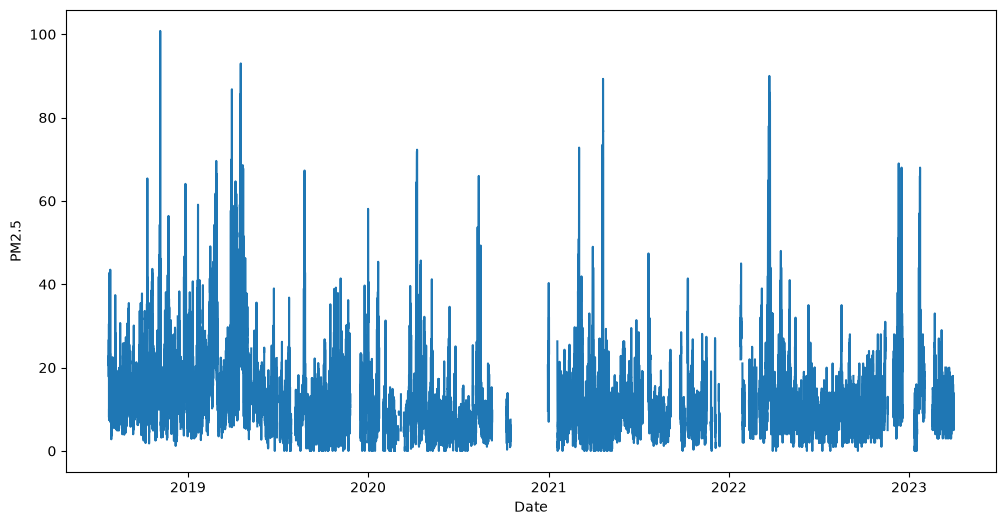

In [215]:
# since every column is filled, we can just chose one to plot
# I chose pm25

plt.figure(figsize=(12, 6))
plt.plot(df_plot['datetime'], df_plot['pm25'])
plt.xlabel('Date')
plt.ylabel('PM2.5')
plt.show()

In [216]:
# save to silver
df_clean.to_csv("../data/silver/my1_cleaned.csv", index=False)

#df_clean_o3.to_csv("../data/silver/my1_cleaned_o3.csv", index=False)
#df_clean_pm25.to_csv("../data/silver/my1_cleaned_pm25.csv", index=False)

In [217]:
metadata = """
pm25 (ugm-3), ozone (ugm-3): from London Marylebone Road (MY1) AURN station
blh (m): from ERA5 reanalysis data, grid cell 51.5000, -0.2500 (~7.1 km from MY1), downloaded from Copernicus Climate Data Store (CDS)
glbl_irad_amt (KJ/m2): from Kew Gardens MIDAS station (~10km from MY1)
prcp_amt (mm): from London St James's Park MIDAS station (~2.5km from MY1)
rltv_hum (%), air_temperature (degC): from London St James's Park MIDAS station (~2.5km from MY1)
wind_speed (knots), wind_direction (true degrees), msl_pressure (hPa): from Battersea Heliport MIDAS station (~5km from MY1)
vehicle_count: from TFL ATC 227 Station
"""